# Build train / validation / test splits (v2 -- leakage fix + 3-regime pooling)

**What changed from the previous version of this notebook:**

1. **Three event-count regimes instead of two.** Pools `ngrip_calibrated_noise_sensitivity_data/` (~15 warming events, actually ~13 -- see its own notebook's naming caveat), `noise_sensitivity_data/` (~25 warming events), and `ngrip_40events_noise_sensitivity_data/` (~40 warming events), each verified clean (no NaNs, no degenerate series) in a separate audit. Train+validation pool from all three, for event-density diversity; test draws **only** from the ~25-event regime, since that's what actually matches NGRIP's ~25 real DO events.
2. **Fixes a real data-leakage bug.** The previous `validation.npz` had 18/20 series (90%) sharing byte-identical `db_true`/`state_true` with a series already in `train.npz` -- only the noise draw differed. Root cause: within each regime folder, `base_seed` (which determines the true trajectory) is deliberately shared across all 9 color/level noise files -- so disjointness has to be enforced at the `(regime, seed)` level, not just by row count or by color/level. This version reserves disjoint seed sub-pools per regime for train/validation/test and explicitly asserts zero overlap on the actual drawn rows, not just on the pool definitions.
3. **Test is filtered to an event-count band near 25**, not just "drawn from the right folder" -- individual seeds in the 25-event regime range from 18-30 warming events, so band-filtering makes the test set's own mean genuinely close to NGRIP's target.
4. **EDA throughout, not just at the end** -- event-count distributions, example time series with warming/cooling marked, inter-transition gap distributions, both on the full pooled catalog and on each final split.

**Not executed automatically end-to-end here** -- run cells yourself; the final save cell will overwrite `train_test_split_data/{train,validation,test}.npz` when you run it.

In [1]:
import os
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.stats import gaussian_kde

REGIME_DIRS = {
    '15event': 'ngrip_calibrated_noise_sensitivity_data',
    '25event': 'noise_sensitivity_data',
    '40event': 'ngrip_40events_noise_sensitivity_data',
}
COLORS = ['white', 'pink', 'red']
LEVELS = ['snr2', 'snr3', 'snr4']
COMBOS = [(c, l) for c in COLORS for l in LEVELS]   # 9 (color, level) combinations
N_SEEDS_PER_REGIME = 20

OUT_DIR = "train_test_split_data"
RANDOM_SEED = 42
os.makedirs(OUT_DIR, exist_ok=True)

REGIME_COLORS = {'15event': '#2a78d6', '25event': '#eb6834', '40event': '#1baf7a'}
SPLIT_COLORS = {'train': '#2a78d6', 'validation': '#eb6834', 'test': '#1baf7a'}
WARM_COLOR, COOL_COLOR = '#2a78d6', '#eb6834'


def transition_times_from_states(time, states):
    change_idx = np.where(np.diff(states) != 0)[0] + 1
    return time[change_idx]


def warming_times_from_states(time, states):
    # 1 (stadial/cold) -> 0 (interstadial/warm): a state DECREASE, diff == -1
    idx = np.where(np.diff(states) == -1)[0] + 1
    return time[idx]


def cooling_times_from_states(time, states):
    idx = np.where(np.diff(states) == 1)[0] + 1
    return time[idx]


def load_condition(regime_dir, color, level):
    return np.load(os.path.join(regime_dir, f"noise_{color}_{level}.npz"))


print("Config loaded.")

Config loaded.


## Section 1 -- Load all three regimes, build a unified catalog

One row per `(regime, color, level, seed)` combination -- 3 regimes x 3 colors x 3 levels x 20 seeds = 540 rows. This catalog drives everything below: the EDA, the seed reservation, and the actual row draws.

In [2]:
catalog_rows = []
regime_data = {}   # (regime_name, color, level) -> npz object, kept open for row extraction later

for regime_name, regime_dir in REGIME_DIRS.items():
    for color, level in COMBOS:
        d = load_condition(regime_dir, color, level)
        regime_data[(regime_name, color, level)] = d
        state_true = d['state_true']
        for s in range(N_SEEDS_PER_REGIME):
            st = state_true[s]
            catalog_rows.append(dict(
                regime=regime_name, color=color, level=level, seed=s,
                n_total=int((np.diff(st) != 0).sum()),
                n_warming=int((np.diff(st) == -1).sum()),
                n_cooling=int((np.diff(st) == 1).sum()),
            ))

catalog = pd.DataFrame(catalog_rows)
print(f"Catalog: {len(catalog)} rows across {catalog['regime'].nunique()} regimes x "
      f"{len(COLORS)} colors x {len(LEVELS)} levels x {N_SEEDS_PER_REGIME} seeds")
catalog.groupby('regime')[['n_total', 'n_warming', 'n_cooling']].agg(['mean', 'std', 'min', 'max'])

Catalog: 540 rows across 3 regimes x 3 colors x 3 levels x 20 seeds


n_total                   n_warming                   n_cooling  \
           mean       std min max      mean       std min max      mean   
regime                                                                    
15event   25.45  5.166799  20  40     12.85  2.600977  10  20     12.60   
25event   44.85  5.710399  35  60     22.60  2.807810  18  30     22.25   
40event   77.60  8.960247  52  95     39.00  4.573423  26  48     38.60   

                           
              std min max  
regime                     
15event  2.584008  10  20  
25event  2.921458  17  30  
40event  4.398578  26  47

## Section 2 -- EDA: warming-event-count distribution by regime

Each regime's 20 base seeds produce a *range* of event counts, not a single fixed number -- this is what the test event-band filter in Section 5 accounts for.

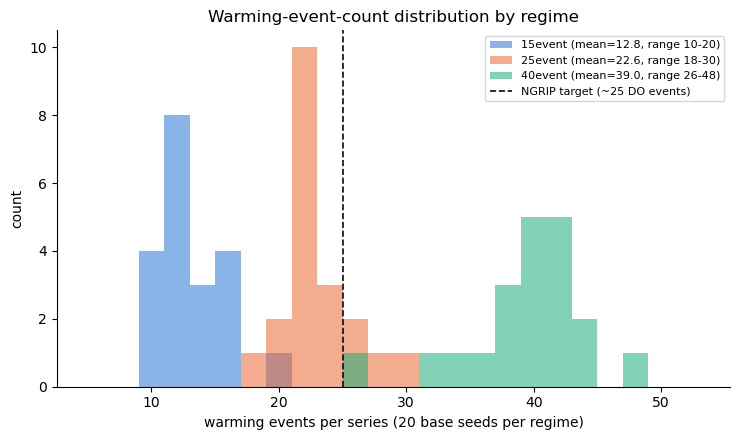

In [3]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for regime_name in REGIME_DIRS:
    sub = catalog[catalog.regime == regime_name]
    # one row per seed (n_warming is identical across all 9 color/level combos for a given seed)
    per_seed = sub[(sub.color == 'red') & (sub.level == 'snr3')]
    ax.hist(per_seed['n_warming'], bins=range(5, 55, 2), alpha=0.55,
            label=f"{regime_name} (mean={per_seed.n_warming.mean():.1f}, range {per_seed.n_warming.min()}-{per_seed.n_warming.max()})",
            color=REGIME_COLORS[regime_name])

ax.axvline(25, color='#0b0b0b', ls='--', lw=1.2, label='NGRIP target (~25 DO events)')
ax.set_xlabel('warming events per series (20 base seeds per regime)')
ax.set_ylabel('count')
ax.set_title('Warming-event-count distribution by regime')
ax.spines[['top', 'right']].set_visible(False)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## Section 3 -- EDA: example time series per regime

One example per regime (red/snr3, seed 0), true + noisy signal, with warming transitions marked blue and cooling transitions marked orange -- so the warming/cooling convention established earlier (`state 1->0` = warming) is visible directly on real data, not just asserted.

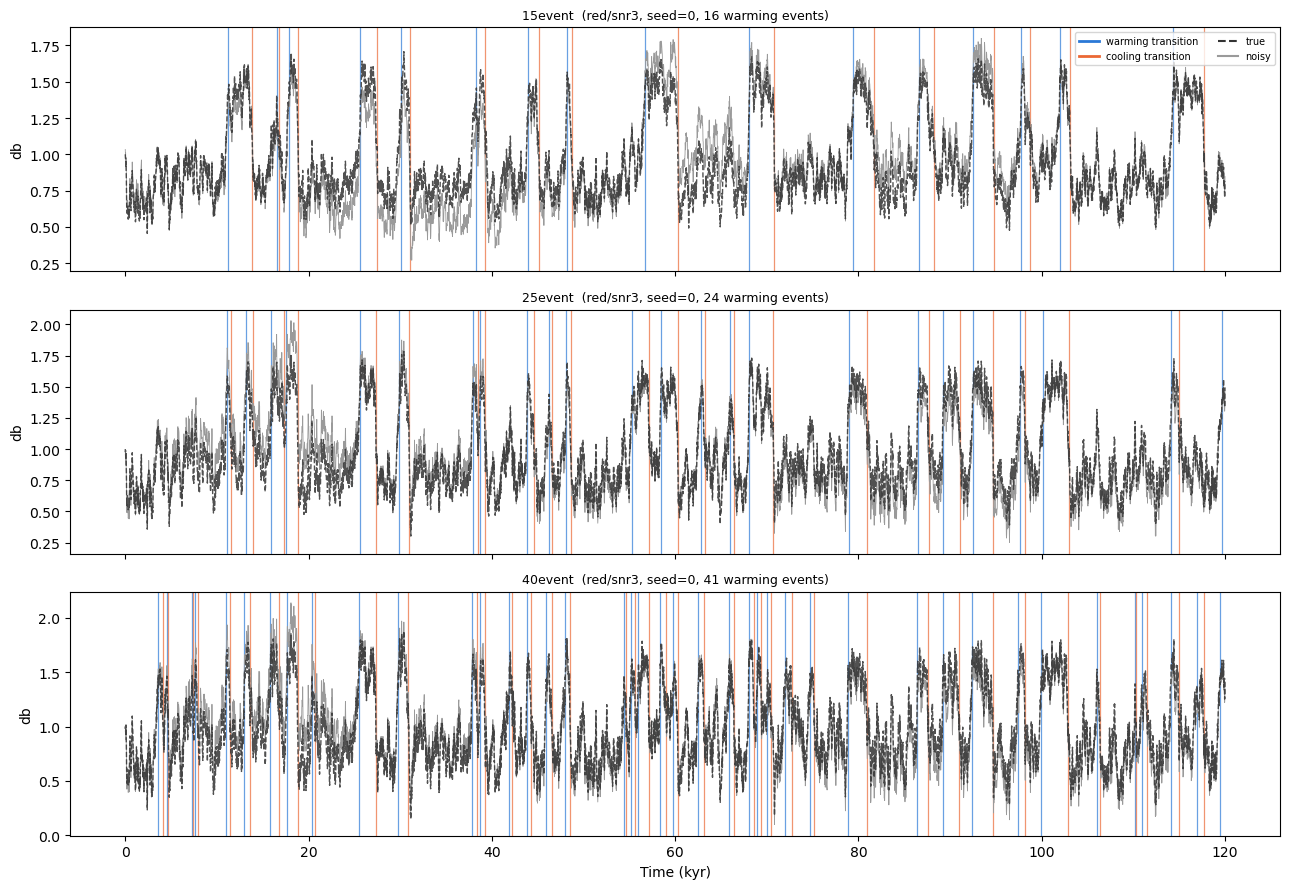

In [4]:
def plot_series_with_transitions(ax, time, db_noisy, db_true, state, title):
    ax.plot(time, db_noisy, lw=0.6, color='#9a9a9a', zorder=1)
    ax.plot(time, db_true, lw=1.0, color='#333333', ls='--', alpha=0.85, zorder=2)
    for t in warming_times_from_states(time, state):
        ax.axvline(t, color=WARM_COLOR, lw=0.9, alpha=0.7, zorder=0)
    for t in cooling_times_from_states(time, state):
        ax.axvline(t, color=COOL_COLOR, lw=0.9, alpha=0.7, zorder=0)
    ax.set_title(title, fontsize=9)
    ax.set_ylabel('db')


fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
for ax, regime_name in zip(axes, REGIME_DIRS):
    d = regime_data[(regime_name, 'red', 'snr3')]
    n_warm = int((np.diff(d['state_true'][0]) == -1).sum())
    plot_series_with_transitions(ax, d['time'], d['db_noisy'][0], d['db_true'][0], d['state_true'][0],
                                  f"{regime_name}  (red/snr3, seed=0, {n_warm} warming events)")

legend_elems = [
    Line2D([0], [0], color=WARM_COLOR, lw=2, label='warming transition'),
    Line2D([0], [0], color=COOL_COLOR, lw=2, label='cooling transition'),
    Line2D([0], [0], color='#333333', lw=1.5, ls='--', label='true'),
    Line2D([0], [0], color='#9a9a9a', lw=1.5, label='noisy'),
]
axes[0].legend(handles=legend_elems, fontsize=7, loc='upper right', ncol=2)
axes[-1].set_xlabel('Time (kyr)')
plt.tight_layout()
plt.show()

## Section 4 -- EDA: inter-transition gap distribution

How closely spaced are consecutive transitions? This matters directly for `min_size` choices downstream (Methods/optuna_search.py) -- a gap shorter than `min_size` samples means a transition is structurally undetectable regardless of tuning. Computed once per regime (red/snr3 only -- ground truth is identical across color/level within a regime, so including all 9 would just duplicate the same gaps 9x).

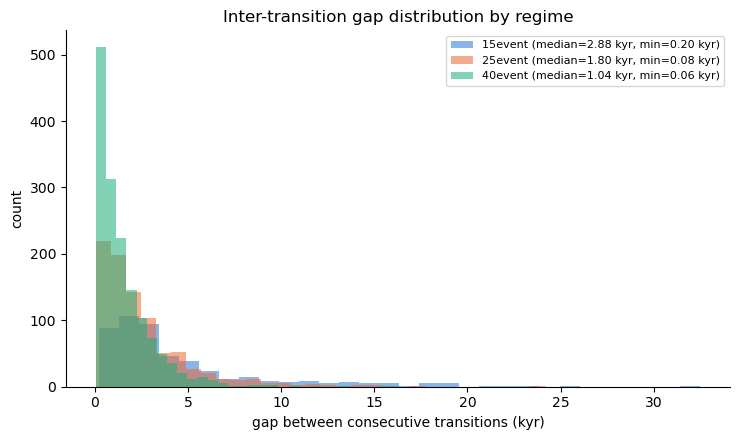

DT=0.02 kyr/sample -- e.g. a 0.8 kyr gap is only 40 samples, right at min_size=40's floor.


In [5]:
gap_rows = []
for regime_name in REGIME_DIRS:
    d = regime_data[(regime_name, 'red', 'snr3')]
    for s in range(N_SEEDS_PER_REGIME):
        t = transition_times_from_states(d['time'], d['state_true'][s])
        for g in np.diff(t):
            gap_rows.append(dict(regime=regime_name, gap_kyr=g))

gap_df = pd.DataFrame(gap_rows)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
for regime_name in REGIME_DIRS:
    sub = gap_df[gap_df.regime == regime_name]['gap_kyr']
    ax.hist(sub, bins=30, alpha=0.55, color=REGIME_COLORS[regime_name],
            label=f"{regime_name} (median={sub.median():.2f} kyr, min={sub.min():.2f} kyr)")

ax.set_xlabel('gap between consecutive transitions (kyr)')
ax.set_ylabel('count')
ax.set_title('Inter-transition gap distribution by regime')
ax.spines[['top', 'right']].set_visible(False)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"DT=0.02 kyr/sample -- e.g. a 0.8 kyr gap is only 40 samples, right at min_size=40's floor.")

## Section 4b -- Statistical comparison to NGRIP (warming-to-warming waiting times)

The Gaussian-KDE justification check from the original notebook (used to justify `sigma=0.5`/25event against NGRIP's real DO-event spacing), generalized here to all three regimes. For each regime, compares the TRUE warming-to-warming waiting-time distribution (pooled across all 20 seeds, red/snr3 -- ground truth doesn't depend on noise) against NGRIP's real DO-to-DO spacing (Rasmussen et al. 2014), via histogram + Gaussian KDE + summary stats (mean, std, median, CV).

In [6]:
from scipy.stats import gaussian_kde

# --- NGRIP + DO event ground truth (warming-only, Rasmussen et al. 2014) ---
ngrip = pd.read_csv("data/NGRIP.csv", skiprows=8, header=None,
                     names=['time', 'd18O', 'extra']).dropna(subset=['time', 'd18O'])
do_df = pd.read_csv("data/DO_events.csv", comment='#')
main_DO = do_df['main_kyr_b2k'].dropna().sort_values().reset_index(drop=True).values
waiting_times_ngrip = np.diff(main_DO)
NGRIP_TARGETS = dict(n_events=len(main_DO), mean_waiting=waiting_times_ngrip.mean(),
                      median_waiting=np.median(waiting_times_ngrip), std_waiting=waiting_times_ngrip.std())
print(f"NGRIP: n_events={NGRIP_TARGETS['n_events']}, mean_waiting={NGRIP_TARGETS['mean_waiting']:.2f} kyr, "
      f"std_waiting={NGRIP_TARGETS['std_waiting']:.2f} kyr")

# --- One representative seed per regime (closest to that regime's own target event count) --
#     a fair one-realization-vs-one-realization comparison against NGRIP's single real record.
#     Pooling all 20 seeds mixes hundreds of gaps against NGRIP's 24, which isn't comparable.
REGIME_TARGETS = {'15event': 15, '25event': 25, '40event': 40}
regime_waiting = {}
regime_repr_seed = {}
for regime_name, target in REGIME_TARGETS.items():
    d = regime_data[(regime_name, 'red', 'snr3')]
    counts = [int((np.diff(d['state_true'][s]) == -1).sum()) for s in range(N_SEEDS_PER_REGIME)]
    best_seed = int(np.argmin([abs(c - target) for c in counts]))
    regime_repr_seed[regime_name] = best_seed
    wt = warming_times_from_states(d['time'], d['state_true'][best_seed])
    regime_waiting[regime_name] = np.diff(wt)
    print(f"{regime_name}: representative seed={best_seed} ({counts[best_seed]} warming events, "
          f"target {target}), mean waiting={regime_waiting[regime_name].mean():.2f} kyr")

NGRIP: n_events=25, mean_waiting=4.08 kyr, std_waiting=3.45 kyr
15event: representative seed=17 (15 warming events, target 15), mean waiting=8.19 kyr
25event: representative seed=4 (25 warming events, target 25), mean waiting=4.59 kyr
40event: representative seed=2 (40 warming events, target 40), mean waiting=3.01 kyr


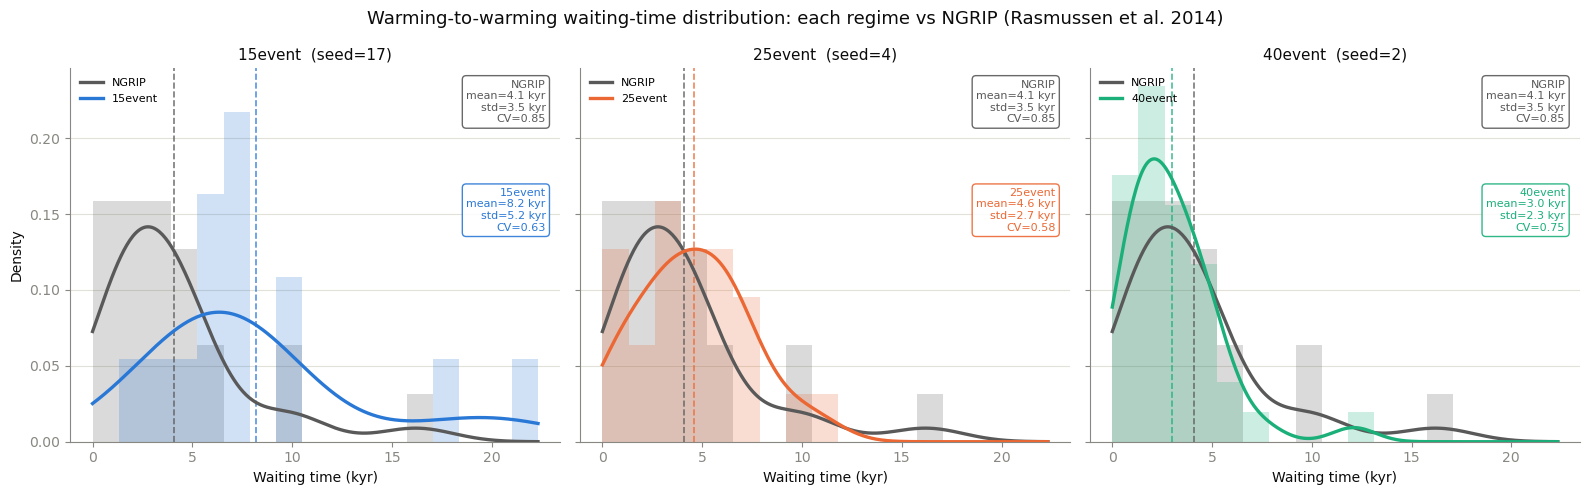

In [7]:
NGRIP_COLOR = '#595959'
GRID_COLOR = '#e1e0d9'
MUTED = '#898781'
INK = '#0b0b0b'


def add_stats_box(ax, waiting, color, y_anchor, label):
    mean, std = np.mean(waiting), np.std(waiting)
    cv = std / mean if mean > 0 else np.nan
    txt = f'{label}\nmean={mean:.1f} kyr\nstd={std:.1f} kyr\nCV={cv:.2f}'
    ax.text(0.97, y_anchor, txt, transform=ax.transAxes, fontsize=8, va='top', ha='right', color=color,
            bbox=dict(boxstyle='round,pad=0.35', fc='white', alpha=0.9, ec=color, lw=1))


all_wt_global = np.concatenate([waiting_times_ngrip] + list(regime_waiting.values()))
bins = np.linspace(0, all_wt_global.max() * 1.05, 18)
x_grid = np.linspace(0, all_wt_global.max() * 1.05, 300)
kde_ngrip = gaussian_kde(waiting_times_ngrip, bw_method='scott')

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)

for ax, regime_name in zip(axes, REGIME_DIRS):
    wt = regime_waiting[regime_name]
    color = REGIME_COLORS[regime_name]

    ax.hist(waiting_times_ngrip, bins=bins, color=NGRIP_COLOR, alpha=0.22, density=True, zorder=1)
    ax.hist(wt, bins=bins, color=color, alpha=0.22, density=True, zorder=1)

    ax.plot(x_grid, kde_ngrip(x_grid), color=NGRIP_COLOR, lw=2.4, label='NGRIP', zorder=3)
    kde_regime = gaussian_kde(wt, bw_method='scott')
    ax.plot(x_grid, kde_regime(x_grid), color=color, lw=2.4, label=regime_name, zorder=3)

    ax.axvline(waiting_times_ngrip.mean(), color=NGRIP_COLOR, ls='--', lw=1.2, alpha=0.8, zorder=2)
    ax.axvline(wt.mean(), color=color, ls='--', lw=1.2, alpha=0.8, zorder=2)

    add_stats_box(ax, waiting_times_ngrip, NGRIP_COLOR, 0.97, 'NGRIP')
    add_stats_box(ax, wt, color, 0.68, regime_name)

    ax.set_title(f'{regime_name}  (seed={regime_repr_seed[regime_name]})', fontsize=11, color=INK)
    ax.set_xlabel('Waiting time (kyr)', color=INK)
    ax.spines[['top', 'right']].set_visible(False)
    ax.spines[['left', 'bottom']].set_color(MUTED)
    ax.tick_params(colors=MUTED)
    ax.yaxis.grid(True, color=GRID_COLOR, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.legend(fontsize=8, frameon=False, loc='upper left')

axes[0].set_ylabel('Density', color=INK)
fig.suptitle('Warming-to-warming waiting-time distribution: each regime vs NGRIP (Rasmussen et al. 2014)',
             fontsize=13, color=INK)
plt.tight_layout()
plt.show()

In [8]:
summary_rows = [dict(source='NGRIP', n_gaps=len(waiting_times_ngrip), mean=waiting_times_ngrip.mean(),
                      std=waiting_times_ngrip.std(), median=np.median(waiting_times_ngrip),
                      cv=waiting_times_ngrip.std() / waiting_times_ngrip.mean())]
for regime_name, wt in regime_waiting.items():
    summary_rows.append(dict(source=regime_name, n_gaps=len(wt), mean=wt.mean(), std=wt.std(),
                              median=np.median(wt), cv=wt.std() / wt.mean()))

pd.DataFrame(summary_rows).round(2)

,source,n_gaps,mean,std,median,cv
0,NGRIP,24,4.08,3.45,3.11,0.85
1,15event,14,8.19,5.19,6.99,0.63
2,25event,24,4.59,2.66,4.49,0.58
3,40event,39,3.01,2.25,2.48,0.75


## Section 5 -- Leakage-safe seed reservation

Each regime's 20 base seeds (0-19) determine the TRUE trajectory (`db_true`/`state_true`) -- shared across all 9 `(color, level)` files within that regime, by design (see `Generate_Data_*events.ipynb`). Disjointness must therefore be enforced at the `(regime, seed)` level, not by row count or by color/level -- this is exactly the check that was missing for train-vs-validation before.

**Allocation:**
- **Test** draws only from `25event`, reserving seeds **14-19** (6 candidates).
- **Train** reserves **0-14** of `15event`/`40event` (15 candidates each) and **0-9** of `25event` (10 candidates).
- **Validation** reserves **15-19** of `15event`/`40event` (5 candidates each) and **10-13** of `25event` (4 candidates).

Every regime's 20 seeds are fully partitioned across the (up to) three pools that touch it, with zero overlap -- verified by assertion immediately below, before anything is drawn.

In [9]:
TEST_SEED_POOL = list(range(14, 20))          # 25event only

TRAIN_SEED_POOLS = {
    '15event': list(range(0, 15)),
    '25event': list(range(0, 10)),
    '40event': list(range(0, 15)),
}
VAL_SEED_POOLS = {
    '15event': list(range(15, 20)),
    '25event': list(range(10, 14)),
    '40event': list(range(15, 20)),
}

# --- Verify disjointness of the POOL DEFINITIONS, before any row is drawn ---
assert set(TRAIN_SEED_POOLS['25event']) & set(VAL_SEED_POOLS['25event']) == set()
assert set(TRAIN_SEED_POOLS['25event']) & set(TEST_SEED_POOL) == set()
assert set(VAL_SEED_POOLS['25event']) & set(TEST_SEED_POOL) == set()
assert (set(TRAIN_SEED_POOLS['25event']) | set(VAL_SEED_POOLS['25event']) | set(TEST_SEED_POOL)
        == set(range(N_SEEDS_PER_REGIME))), "25event seed pools don't fully partition 0-19"

for regime_name in ('15event', '40event'):
    assert set(TRAIN_SEED_POOLS[regime_name]) & set(VAL_SEED_POOLS[regime_name]) == set()
    assert (set(TRAIN_SEED_POOLS[regime_name]) | set(VAL_SEED_POOLS[regime_name])
            == set(range(N_SEEDS_PER_REGIME))), f"{regime_name} seed pools don't fully partition 0-19"

print("Seed-pool disjointness verified for all three splits, across all three regimes, before drawing anything.")
print(f"  test:       25event seeds {TEST_SEED_POOL}")
print(f"  train:      15event {TRAIN_SEED_POOLS['15event']} | 25event {TRAIN_SEED_POOLS['25event']} | "
      f"40event {TRAIN_SEED_POOLS['40event']}")
print(f"  validation: 15event {VAL_SEED_POOLS['15event']} | 25event {VAL_SEED_POOLS['25event']} | "
      f"40event {VAL_SEED_POOLS['40event']}")

Seed-pool disjointness verified for all three splits, across all three regimes, before drawing anything.
  test:       25event seeds [14, 15, 16, 17, 18, 19]
  train:      15event [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14] | 25event [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] | 40event [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]
  validation: 15event [15, 16, 17, 18, 19] | 25event [10, 11, 12, 13] | 40event [15, 16, 17, 18, 19]


## Section 6 -- Test candidates: filter to a ~25-warming-event band

Not every seed in `25event`'s reserved test pool is actually close to 25 warming events (the regime's own range is 18-30). Filtering to a band around 25 makes the test set's mean genuinely close to NGRIP's target, not just drawn from the right folder.

In [10]:
EVENT_BAND_LOW, EVENT_BAND_HIGH = 20, 30

test_pool_events = catalog[(catalog.regime == '25event') & (catalog.color == 'red') &
                            (catalog.level == 'snr3') & (catalog.seed.isin(TEST_SEED_POOL))]
print("Test seed pool, warming-event count per seed (red/snr3 representative -- identical across color/level):")
print(test_pool_events[['seed', 'n_warming']].to_string(index=False))

in_band = test_pool_events[(test_pool_events.n_warming >= EVENT_BAND_LOW) &
                            (test_pool_events.n_warming <= EVENT_BAND_HIGH)]
TEST_SEED_CANDIDATES = sorted(in_band['seed'].tolist())
assert len(TEST_SEED_CANDIDATES) >= 3, (
    f"Only {len(TEST_SEED_CANDIDATES)} test seeds land in the {EVENT_BAND_LOW}-{EVENT_BAND_HIGH} band -- "
    f"widen EVENT_BAND_LOW/HIGH or TEST_SEED_POOL."
)
print(f"\nIn-band ({EVENT_BAND_LOW}-{EVENT_BAND_HIGH}) test seed candidates: {TEST_SEED_CANDIDATES}")

Test seed pool, warming-event count per seed (red/snr3 representative -- identical across color/level):
 seed  n_warming
   14         28
   15         22
   16         21
   17         22
   18         19
   19         25

In-band (20-30) test seed candidates: [14, 15, 16, 17, 19]


## Section 7 -- Draw the actual series

`TEST_TARGET=20` (25event only, in-band seeds, spread across the 9 color/level combos). `TRAIN_TARGET=60` + `VAL_TARGET=20` pooled roughly equally across all three regimes, each combo's seeds drawn from that split's reserved pool for that regime.

In [11]:
rng = np.random.default_rng(RANDOM_SEED)


def draw_seeds(candidates, n, rng):
    candidates = list(candidates)
    replace = n > len(candidates)
    return rng.choice(candidates, size=n, replace=replace)


def spread_counts(total, n_bins, rng):
    """Split `total` into `n_bins` near-equal integer counts (sums to `total` exactly)."""
    base = total // n_bins
    rem = total - base * n_bins
    counts = [base] * n_bins
    for i in rng.choice(n_bins, size=rem, replace=False):
        counts[i] += 1
    return counts


def make_row(regime_name, color, level, seed):
    d = regime_data[(regime_name, color, level)]
    meta = catalog[(catalog.regime == regime_name) & (catalog.color == color) &
                    (catalog.level == level) & (catalog.seed == seed)].iloc[0]
    return dict(source=regime_name, color=color, level=level, seed=int(seed),
                time=d['time'], db_true=d['db_true'][seed], db_noisy=d['db_noisy'][seed],
                state_true=d['state_true'][seed], state_observed=d['state_observed'][seed],
                n_events=int(meta['n_total']), n_warming=int(meta['n_warming']), n_cooling=int(meta['n_cooling']))


# --- Test: 25event only, in-band seeds ---
TEST_TARGET = 20
test_counts = spread_counts(TEST_TARGET, len(COMBOS), rng)
test_rows = []
for (color, level), n in zip(COMBOS, test_counts):
    for s in draw_seeds(TEST_SEED_CANDIDATES, n, rng):
        test_rows.append(make_row('25event', color, level, s))
assert len(test_rows) == TEST_TARGET

# --- Train: pooled across all 3 regimes ---
# UNCHANGED vs the previous version of this notebook -- deliberately still consuming the
# same shared `rng` object, in the same call order, as before, so re-running this cell
# reproduces the EXACT same train_rows already saved to train.npz/train_manifest.csv.
# Train's own (color, level) coverage already guarantees >=2 series per combo per regime
# (n_train=20 per regime >= the 9 combos), so it never needed the fix Section 7bis applies
# to validation -- see that section's markdown for why validation did.
TRAIN_TARGET = 60
REGIME_NAMES = list(REGIME_DIRS.keys())
train_per_regime = spread_counts(TRAIN_TARGET, len(REGIME_NAMES), rng)

train_rows = []
for regime_name, n_train in zip(REGIME_NAMES, train_per_regime):
    for (color, level), nt in zip(COMBOS, spread_counts(n_train, len(COMBOS), rng)):
        for s in draw_seeds(TRAIN_SEED_POOLS[regime_name], nt, rng):
            train_rows.append(make_row(regime_name, color, level, s))

assert len(train_rows) == TRAIN_TARGET
print(f"Built test={len(test_rows)}  train={len(train_rows)}")
print(f"Train per regime: {dict(zip(REGIME_NAMES, train_per_regime))}")

Built test=20  train=60
Train per regime: {'15event': 20, '25event': 20, '40event': 20}


## Section 7bis -- Validation: fixed (color, level) coverage

**Bug in the previous version of this notebook:** validation's 20 series were split by
REGIME first (~6-7 each, via the same interleaved loop train used above), then by
color/level *within* each regime's ~6-7 share. Since 6-7 < 9 (the number of `(color,
level)` combos), `spread_counts` could only hit 6-7 of the 9 combos per regime and left
the rest at implicit 0 -- independently, per regime. `red/snr2` ended up excluded in all
three regimes' random picks under `RANDOM_SEED=42`, landing at literally 0 series in the
whole validation set (`red/snr3` similarly thin, at 1). Confirmed via
`train_test_split_data/validation_manifest.csv`'s actual color x level cross-tab.

**Fix:** flip the nesting order, the same way test already (correctly) works -- spread
`VAL_TARGET=20` across the 9 combos FIRST (20 >= 9 guarantees every combo gets >= 2,
exactly like test's own >= 2 guarantee), THEN spread each combo's small count across the
3 regimes. This can leave some individual `(regime, combo)` cells at 0 -- a combo with
only 2 series might miss one of the 3 regimes -- which is fine: regime coverage and
color/level coverage are each their own separate requirement (see
`check_split_coverage.py`), not a full 27-cell `(regime x color x level)` cross, which
isn't achievable at n=20 without a much larger validation set.

Uses its own `VAL_RNG`, seeded independently from the `rng` object test/train consume
above -- deliberately, so this fix cannot perturb train_rows/test_rows' random draws at
all. Re-running this whole notebook after this fix reproduces byte-identical
`train.npz`/`test.npz` to what's already saved; only `validation.npz`/
`validation_manifest.csv` change (see Section 11 -- only validation is saved there now).

In [12]:
VAL_RANDOM_SEED = RANDOM_SEED   # separate generator, same seed VALUE -- see Section 7bis markdown
VAL_RNG = np.random.default_rng(VAL_RANDOM_SEED)

VAL_TARGET = 20
val_rows = []
for (color, level), n_combo in zip(COMBOS, spread_counts(VAL_TARGET, len(COMBOS), VAL_RNG)):
    for regime_name, n_regime in zip(REGIME_NAMES, spread_counts(n_combo, len(REGIME_NAMES), VAL_RNG)):
        for s in draw_seeds(VAL_SEED_POOLS[regime_name], n_regime, VAL_RNG):
            val_rows.append(make_row(regime_name, color, level, s))

assert len(val_rows) == VAL_TARGET

val_combo_counts = pd.Series([(r['color'], r['level']) for r in val_rows]).value_counts()
assert len(val_combo_counts) == len(COMBOS), (
    f"validation still missing {len(COMBOS) - len(val_combo_counts)} (color, level) combo(s) -- "
    f"got {sorted(val_combo_counts.index.tolist())}"
)
val_regime_counts = pd.Series([r['source'] for r in val_rows]).value_counts()
assert set(val_regime_counts.index) == set(REGIME_NAMES), (
    f"validation missing a regime entirely -- got {sorted(val_regime_counts.index.tolist())}"
)

print(f"Built validation={len(val_rows)}  "
      f"(all {len(COMBOS)} color/level combos covered, all {len(REGIME_NAMES)} regimes covered)")
print(f"Validation per (color, level):\n{val_combo_counts.sort_index()}")
print(f"Validation per regime: {dict(val_regime_counts)}")

Built validation=20  (all 9 color/level combos covered, all 3 regimes covered)
Validation per (color, level):
(pink, snr2)     2
(pink, snr3)     2
(pink, snr4)     2
(red, snr2)      3
(red, snr3)      2
(red, snr4)      2
(white, snr2)    3
(white, snr3)    2
(white, snr4)    2
Name: count, dtype: int64
Validation per regime: {'15event': 8, '25event': 6, '40event': 6}


## Section 8 -- Verify zero leakage on the actual drawn rows

Not just the pool definitions this time -- the real check is on what actually got drawn, keyed by `(source regime, seed)` since that's what determines the true trajectory.

In [13]:
def keyset(rows):
    return set((r['source'], r['seed']) for r in rows)


k_train, k_val, k_test = keyset(train_rows), keyset(val_rows), keyset(test_rows)

overlap_tv = k_train & k_val
overlap_tt = k_train & k_test
overlap_vt = k_val & k_test

assert not overlap_tv, f"LEAKAGE train/validation: {overlap_tv}"
assert not overlap_tt, f"LEAKAGE train/test: {overlap_tt}"
assert not overlap_vt, f"LEAKAGE validation/test: {overlap_vt}"

print("VERIFIED: zero (source, seed) overlap between train, validation, and test -- on the actual drawn rows.")
print(f"  train uses {len(k_train)} distinct (regime, seed) pairs across {len(train_rows)} rows "
      f"({len(train_rows) - len(k_train)} repeats from draw-with-replacement, expected)")
print(f"  validation uses {len(k_val)} distinct pairs across {len(val_rows)} rows")
print(f"  test uses {len(k_test)} distinct pairs across {len(test_rows)} rows")

VERIFIED: zero (source, seed) overlap between train, validation, and test -- on the actual drawn rows.
  train uses 30 distinct (regime, seed) pairs across 60 rows (30 repeats from draw-with-replacement, expected)
  validation uses 11 distinct pairs across 20 rows
  test uses 5 distinct pairs across 20 rows


## Section 9 -- EDA: does the split actually look like it's supposed to?

Event-count distribution per split (test should cluster near 25; train/validation should each span the full 13-40 range from pooling all three regimes) and the regime/color/level composition of each.

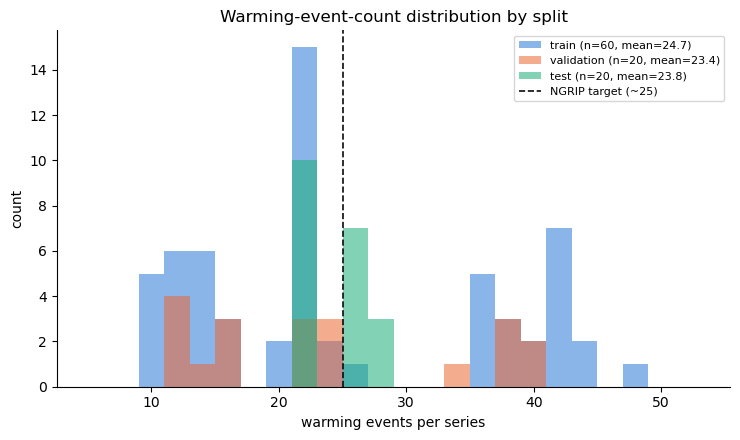

In [14]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for split_name, rows in (('train', train_rows), ('validation', val_rows), ('test', test_rows)):
    vals = [r['n_warming'] for r in rows]
    ax.hist(vals, bins=range(5, 55, 2), alpha=0.55, color=SPLIT_COLORS[split_name],
            label=f"{split_name} (n={len(rows)}, mean={np.mean(vals):.1f})")

ax.axvline(25, color='#0b0b0b', ls='--', lw=1.2, label='NGRIP target (~25)')
ax.set_xlabel('warming events per series')
ax.set_ylabel('count')
ax.set_title('Warming-event-count distribution by split')
ax.spines[['top', 'right']].set_visible(False)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [15]:
def composition_table(rows, name):
    df = pd.DataFrame([{'source': r['source'], 'color': r['color'], 'level': r['level']} for r in rows])
    print(f"--- {name} composition (n={len(rows)}) ---")
    print(df.groupby(['source']).size().rename('n_series').to_string())
    print()


composition_table(train_rows, 'train')
composition_table(val_rows, 'validation')
composition_table(test_rows, 'test')

--- train composition (n=60) ---
source
15event    20
25event    20
40event    20

--- validation composition (n=20) ---
source
15event    8
25event    6
40event    6

--- test composition (n=20) ---
source
25event    20



## Section 10 -- EDA: one example series per split

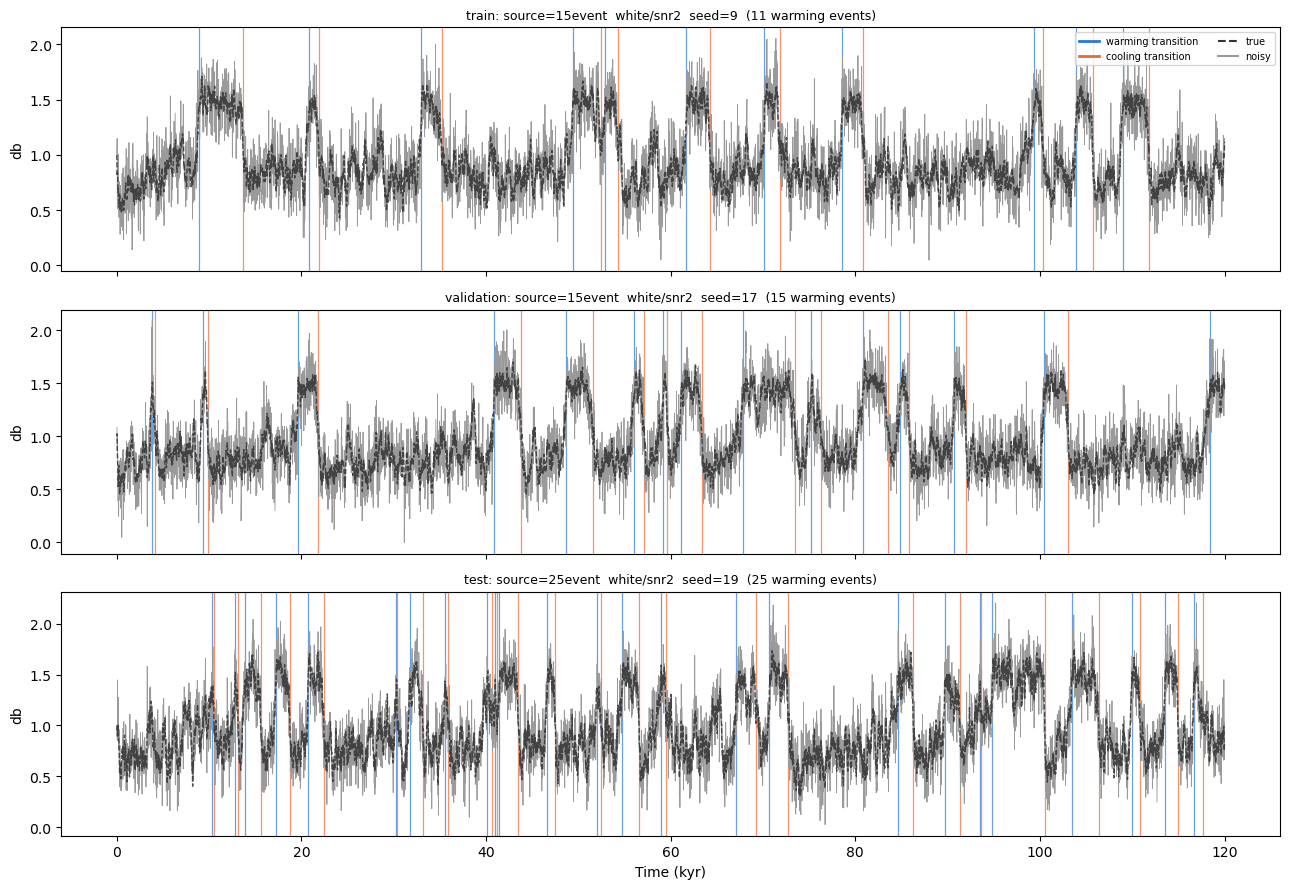

In [16]:
fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
for ax, (split_name, rows) in zip(axes, (('train', train_rows), ('validation', val_rows), ('test', test_rows))):
    r = rows[0]
    plot_series_with_transitions(ax, r['time'], r['db_noisy'], r['db_true'], r['state_true'],
                                  f"{split_name}: source={r['source']}  {r['color']}/{r['level']}  "
                                  f"seed={r['seed']}  ({r['n_warming']} warming events)")

axes[0].legend(handles=legend_elems, fontsize=7, loc='upper right', ncol=2)
axes[-1].set_xlabel('Time (kyr)')
plt.tight_layout()
plt.show()

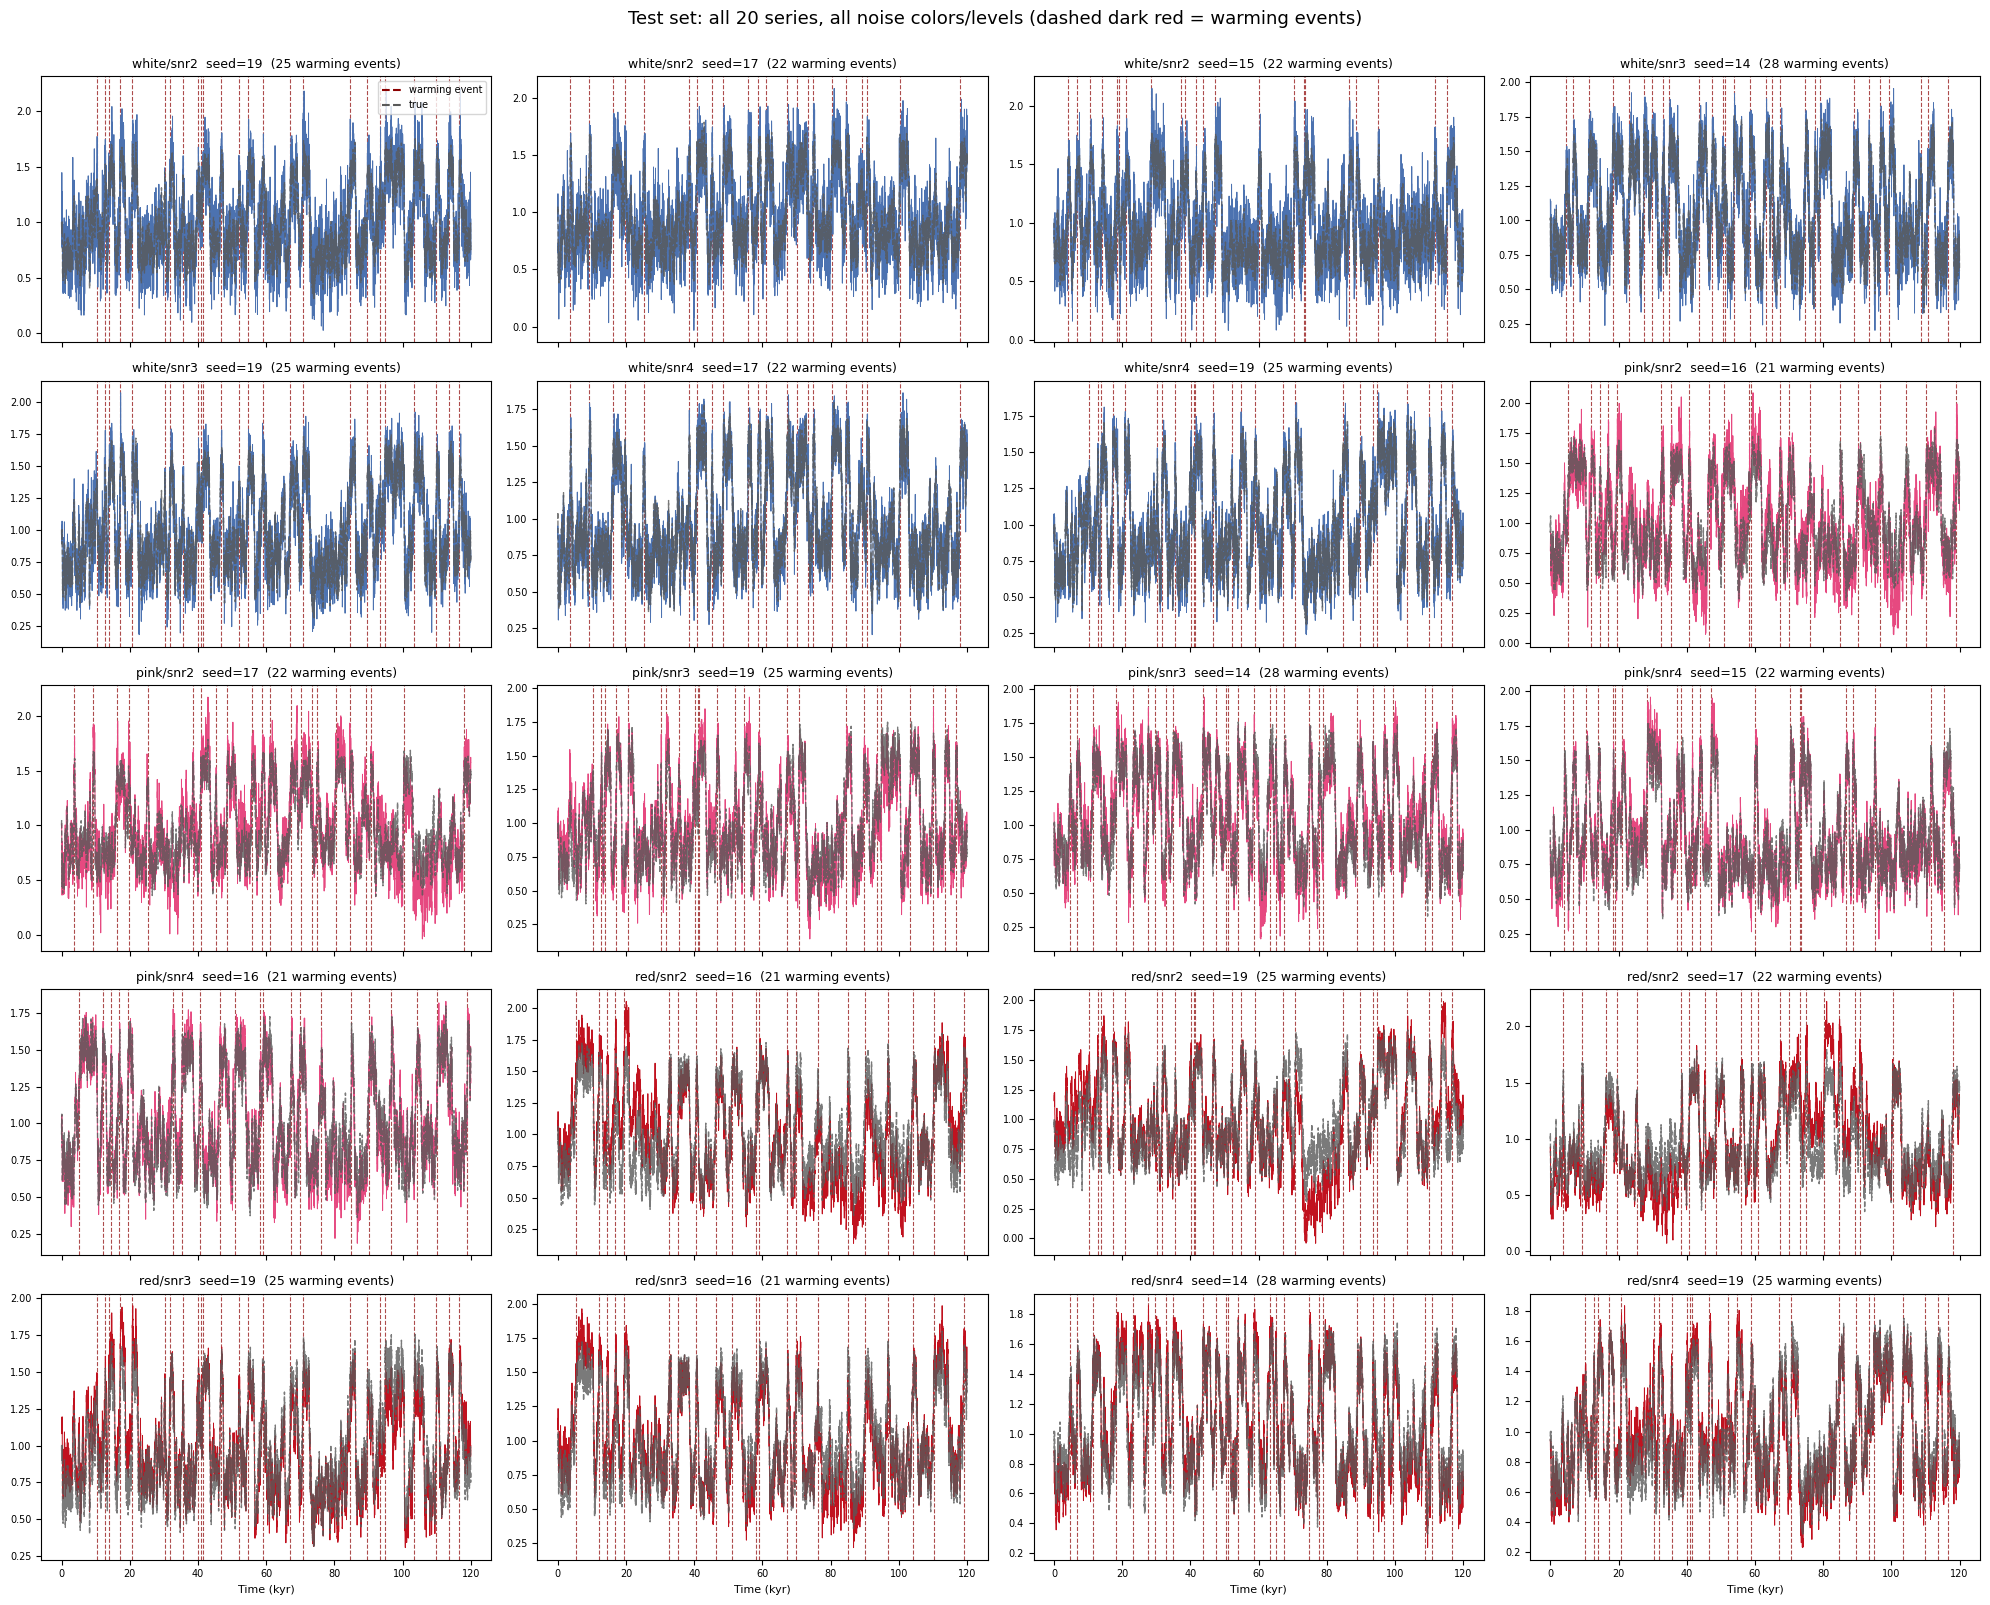

In [17]:
WARM_LINE_COLOR = '#8b0000'   # dashed dark red for warming events
NOISE_PLOT_COLORS = {'white': '#4c72b0', 'pink': '#e64980', 'red': '#c1121f'}

ncols = 4
nrows = int(np.ceil(len(test_rows) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.2 * nrows), sharex=True)
axes = axes.flatten()

for ax, r in zip(axes, test_rows):
    ax.plot(r['time'], r['db_noisy'], lw=0.7, color=NOISE_PLOT_COLORS[r['color']], label='noisy')
    ax.plot(r['time'], r['db_true'], lw=1.0, color='#595959', ls='--', alpha=0.8, label='true')
    for t in warming_times_from_states(r['time'], r['state_true']):
        ax.axvline(t, color=WARM_LINE_COLOR, ls='--', lw=0.8, alpha=0.7, zorder=0)
    ax.set_title(f"{r['color']}/{r['level']}  seed={r['seed']}  ({r['n_warming']} warming events)", fontsize=9)
    ax.tick_params(labelsize=7)

for j in range(len(test_rows), len(axes)):
    axes[j].axis('off')

legend_elems = [
    Line2D([0], [0], color=WARM_LINE_COLOR, lw=1.5, ls='--', label='warming event'),
    Line2D([0], [0], color='#595959', lw=1.5, ls='--', label='true'),
]
axes[0].legend(handles=legend_elems, fontsize=7, loc='upper right')
for ax in axes[max(0, len(test_rows) - ncols):len(test_rows)]:
    ax.set_xlabel('Time (kyr)', fontsize=8)

fig.suptitle(f"Test set: all {len(test_rows)} series, all noise colors/levels "
             f"(dashed dark red = warming events)", y=1.0, fontsize=13)
plt.tight_layout()
plt.show()

In [18]:
test_n_warming = [r['n_warming'] for r in test_rows]
test_n_cooling = [r['n_cooling'] for r in test_rows]
test_n_events = [r['n_events'] for r in test_rows]

print(f"Test set (n={len(test_rows)} series):")
print(f"  n_warming (target ~25): mean={np.mean(test_n_warming):.2f}  std={np.std(test_n_warming):.2f}  "
      f"min={np.min(test_n_warming)}  max={np.max(test_n_warming)}")
print(f"  n_cooling:              mean={np.mean(test_n_cooling):.2f}  std={np.std(test_n_cooling):.2f}  "
      f"min={np.min(test_n_cooling)}  max={np.max(test_n_cooling)}")
print(f"  n_events (total):       mean={np.mean(test_n_events):.2f}  std={np.std(test_n_events):.2f}  "
      f"min={np.min(test_n_events)}  max={np.max(test_n_events)}")

Test set (n=20 series):
  n_warming (target ~25): mean=23.75  std=2.38  min=21  max=28
  n_cooling:              mean=23.35  std=2.78  min=20  max=28
  n_events (total):       mean=47.10  std=5.16  min=41  max=56


## Section 11 -- Save datasets

Overwrites `train_test_split_data/{train,validation,test}.npz` + their manifests. Manifests now also record `n_warming`/`n_cooling`, not just total `n_events`.

In [19]:
def save_split(rows, name):
    n = len(rows)
    time_ref = rows[0]['time']
    arrs = {k: np.vstack([r[k] for r in rows]) for k in ('db_true', 'db_noisy', 'state_true', 'state_observed')}

    np.savez(os.path.join(OUT_DIR, f"{name}.npz"), time=time_ref, seeds=np.arange(n), **arrs)

    manifest = pd.DataFrame([{
        'row': i, 'source': r['source'], 'color': r['color'], 'level': r['level'],
        'orig_seed': r['seed'], 'n_events': r['n_events'],
        'n_warming': r['n_warming'], 'n_cooling': r['n_cooling'],
    } for i, r in enumerate(rows)])
    manifest.to_csv(os.path.join(OUT_DIR, f"{name}_manifest.csv"), index=False)
    return manifest


# Only validation is (re)saved here -- train.npz/train_manifest.csv and test.npz/
# test_manifest.csv are deliberately left untouched on disk. Their row-generation logic
# didn't change (see Section 7bis), and train_rows/test_rows are reproduced byte-identical
# to what's already saved, so there is nothing to gain from rewriting them and doing so
# would only risk invalidating optuna_search(_pruning).py's train_data_hash check against
# any accumulated study for no reason.
val_manifest = save_split(val_rows, "validation")

print(f"Saved {OUT_DIR}/validation.npz + validation_manifest.csv ({len(val_rows)} series). "
      f"train.npz/test.npz intentionally left untouched -- run check_split_coverage.py "
      f"next to verify all three splits.")

Saved train_test_split_data/validation.npz + validation_manifest.csv (20 series). train.npz/test.npz intentionally left untouched -- run check_split_coverage.py next to verify all three splits.


## Section 12 -- Verify: coverage + zero leakage, on what's actually on disk

Runs `check_split_coverage.py` against the just-saved manifest CSVs (not the in-memory
`train_rows`/`val_rows`/`test_rows` -- this is deliberately a check on what a downstream
script like `optuna_search_pruning.py` will actually load). It re-verifies, for every
split:

1. **All 9 `(color, level)` combos present** -- this is the check that would have caught
   validation's `red/snr2 = 0` bug before it went unnoticed (see Section 7bis).
2. **Event-count regime (category) coverage** -- train and validation must each contain
   all three regimes (15/25/40 events); test must contain **only** the 25-event regime.
3. **Zero cross-split leakage** -- no `(source, orig_seed)` pair (which fixes the TRUE
   trajectory) appears in more than one split. Section 8 above already checks this on
   the in-memory rows; this repeats it on disk as a final, independent confirmation.

Raises if anything fails -- a notebook run that reaches this cell without error means
the saved `train.npz`/`validation.npz`/`test.npz` are known-good on all three counts.

In [20]:
import subprocess
import sys

check_script = os.path.join(OUT_DIR, "check_split_coverage.py")
result = subprocess.run([sys.executable, check_script, "--split-dir", OUT_DIR],
                         capture_output=True, text=True)
print(result.stdout)
if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError(
        f"{check_script} FAILED (exit code {result.returncode}) -- see output above. "
        f"Do not trust the saved splits until this passes."
    )
print("Section 12: PASSED -- all three splits verified on disk.")

=== (color, level) coverage -- required in every split ===
  (train) color x level coverage: OK -- 9/9 combos present
  (validation) color x level coverage: OK -- 9/9 combos present
  (test) color x level coverage: OK -- 9/9 combos present

=== event-count regime (category) coverage ===
  (train) regime coverage: OK -- present=['15event', '25event', '40event']  required=['15event', '25event', '40event']
  (validation) regime coverage: OK -- present=['15event', '25event', '40event']  required=['15event', '25event', '40event']
  (test) regime coverage: OK -- present=['25event']  required=['25event']

=== cross-split leakage ===
  cross-split (source, orig_seed) leakage check: OK

=== within-split duplicates (informational) ===
  (train) within-split duplicates: none
  (validation) within-split duplicates: none
  (test) within-split duplicates: none

ALL REQUIRED CHECKS PASSED.

Section 12: PASSED -- all three splits verified on disk.


## Section 13 -- Walkthrough: what happens to ONE time series

Everything above builds the splits. This section follows a **single** series from start to finish, showing every transformation the data goes through before detection (no training / optimization here). Part A is a synthetic series, Part B is NGRIP.

Both parts end in the same place: a **standardized, forward-time series** (zero mean, unit variance, time running forward) -- the form the detection methods receive.

### Part A -- one synthetic series
Example: the test series with red noise at SNR 3 and exactly 25 warming events (test row 16, loaded from the saved `test.npz`).

| Step | What happens |
|---|---|
| 1. Model output | Melcher bistable model, 0-120 kyr, dt = 0.02 kyr (6001 points). Noise-free trajectory, so the true warming events are known (marked with dashed dark-red lines). |
| 2. Add noise | Red noise at SNR 3 is added to mimic measurement error (noisy series drawn in red over the noise-free original, in gray). |
| 3. Standardize | The noisy series is rescaled to zero mean and unit variance, using its own mean and std (shown alone, in red). |
| (no flip) | The model already runs forward in time, so there is no axis flip for synthetic data. |

series: 25event, red/snr3, 6001 points, 0-120 kyr, 25 warming events


,mean,std,min,max
step,,,,
1. model output (noise-free),0.99,0.323,0.310,1.752
"2. + noise (red, SNR 3)",0.99,0.322,0.309,1.946
3. standardized,0.00,1.000,-2.114,2.966


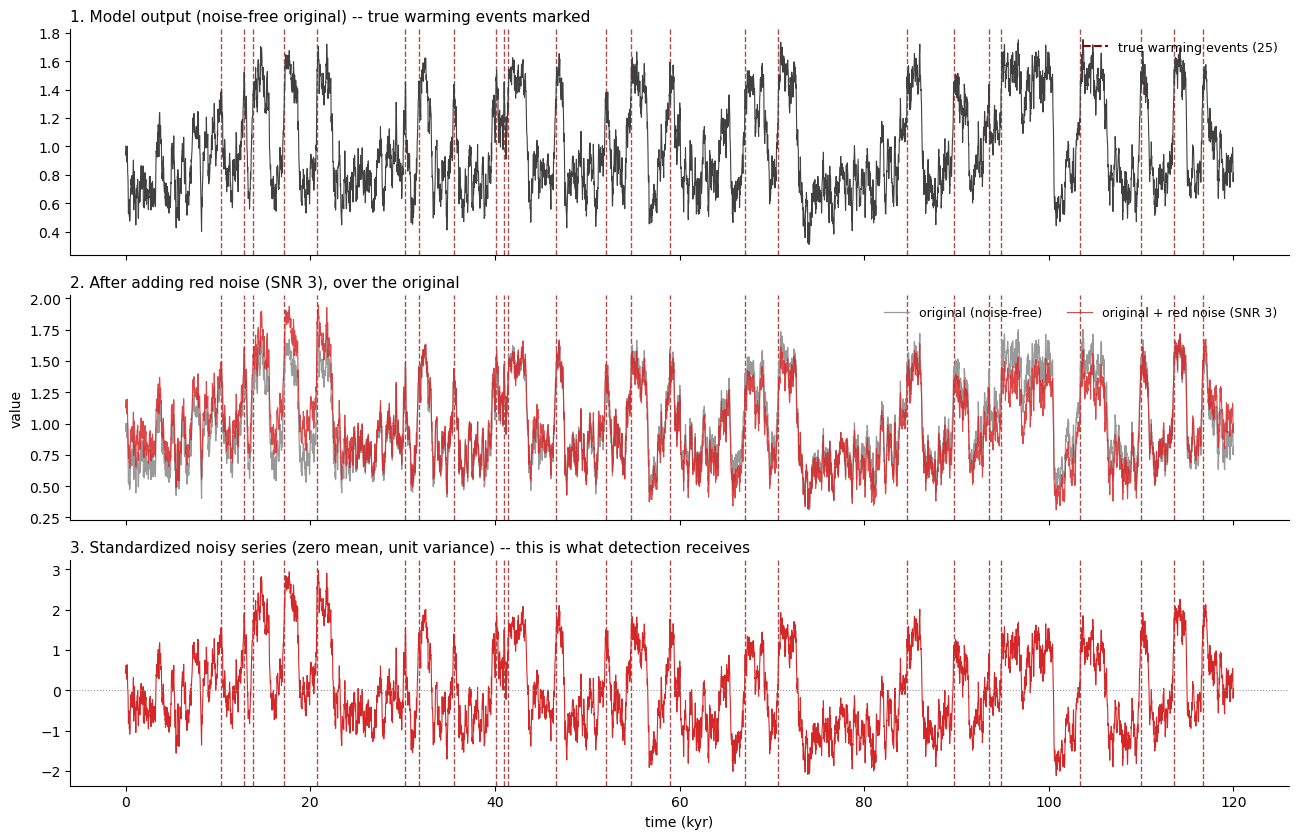

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from pyleoclim.utils.tsutils import standardize as pyleo_standardize
except ImportError:
    pyleo_standardize = None

def standardize_1d(x):
    """zero mean / unit std from the series' own stats (same as the pyleoclim call used in load_split)."""
    if pyleo_standardize is not None:
        return np.asarray(pyleo_standardize(np.asarray(x, float))[0])
    x = np.asarray(x, float)
    return (x - x.mean()) / x.std(ddof=1)

WARM_COLOR = '#8b0000'   # dark red, dashed

split_dir = "train_test_split_data"
test = np.load(os.path.join(split_dir, "test.npz"))
test_manifest = pd.read_csv(os.path.join(split_dir, "test_manifest.csv"))

row = 16   # red / snr3 / 25 warming events
info = test_manifest.loc[row]
assert (info.color, info.level, info.n_warming) == ("red", "snr3", 25), info

t = test["time"]
x_true = test["db_true"][row]        # step 1: noise-free model output
x_noisy = test["db_noisy"][row]      # step 2: + red noise (SNR 3)
x_std = standardize_1d(x_noisy)      # step 3: standardized
state = test["state_true"][row]

# ground truth: state 1 -> 0 is a warming (only warming events are marked; the target, NGRIP DO events, is warming-only)
warm_t = t[np.where(np.diff(state) == -1)[0] + 1]

summary = pd.DataFrame({
    "step": ["1. model output (noise-free)", "2. + noise (red, SNR 3)", "3. standardized"],
    "mean": [x_true.mean(), x_noisy.mean(), x_std.mean()],
    "std":  [x_true.std(ddof=1), x_noisy.std(ddof=1), x_std.std(ddof=1)],
    "min":  [x_true.min(), x_noisy.min(), x_std.min()],
    "max":  [x_true.max(), x_noisy.max(), x_std.max()],
}).set_index("step").round(3)
print(f"series: {info.source}, {info.color}/{info.level}, {len(t)} points, "
      f"{t.min():.0f}-{t.max():.0f} kyr, {len(warm_t)} warming events")
display(summary)

NOISE_COLOR = {"red": "#d62728", "pink": "#e377c2", "white": "0.45"}[info.color]

fig, axes = plt.subplots(3, 1, figsize=(13, 8.5), sharex=True)

# 1. noise-free original
axes[0].plot(t, x_true, color="0.25", linewidth=0.8)
axes[0].set_title("1. Model output (noise-free original) -- true warming events marked", loc="left", fontsize=11)

# 2. noisy series (noise color) drawn over the original (gray)
axes[1].plot(t, x_true, color="0.6", linewidth=0.9, label="original (noise-free)")
axes[1].plot(t, x_noisy, color=NOISE_COLOR, linewidth=0.8, alpha=0.85, label=f"original + {info.color} noise (SNR 3)")
axes[1].set_title(f"2. After adding {info.color} noise (SNR 3), over the original", loc="left", fontsize=11)
axes[1].legend(loc="upper right", fontsize=9, ncol=2, frameon=False)

# 3. standardized noisy series only, same color
axes[2].plot(t, x_std, color=NOISE_COLOR, linewidth=0.8)
axes[2].axhline(0, color="0.6", linewidth=0.8, linestyle=":")
axes[2].set_title("3. Standardized noisy series (zero mean, unit variance) -- this is what detection receives", loc="left", fontsize=11)
axes[2].set_xlabel("time (kyr)")

for ax in axes:
    for w in warm_t:
        ax.axvline(w, color=WARM_COLOR, linestyle="--", alpha=0.7, linewidth=1.0, zorder=0)
    ax.spines[["top", "right"]].set_visible(False)
axes[1].set_ylabel("value")
axes[0].plot([], [], color=WARM_COLOR, linestyle="--", label=f"true warming events ({len(warm_t)})")
axes[0].legend(loc="upper right", fontsize=9, frameon=False)
fig.tight_layout()
plt.show()


### Part B -- NGRIP (real data)

NGRIP needs two extra steps compared with the synthetic series, because its time axis is an **age** (kyr before 2000 AD, increasing into the past) while the synthetic series and the detection tuning run **forward in time**.

| Step | What happens |
|---|---|
| 1. Raw record | NGRIP delta-18-O on the age axis (kyr b2k), with the 25 main DO warming onsets (Rasmussen et al. 2014). |
| 2. Slice | Cut to the DO-catalog window (first to last onset) plus 2 kyr of padding on each side, so the detector has context at the edges. |
| 3. Flip the axis | time = -age (now increasing forward) and the values reversed to match; the DO onsets are flipped the same way (-age). A warming is now the value going *up*, as in the synthetic data. |
| 4. Standardize | Zero mean and unit variance, from NGRIP's own statistics, the same treatment the synthetic series received. |

25 DO onsets, 14.69-115.37 kyr b2k


,points,time range,mean,std
step,,,,
1. raw record,6113,0.0 to 122.3 kyr b2k,-39.942,2.968
2. sliced window,5234,12.7 to 117.4 kyr b2k,-40.705,2.383
3. flipped (forward time),5234,-117.4 to -12.7 (-kyr b2k),-40.705,2.383
4. standardized,5234,-117.4 to -12.7 (-kyr b2k),0.000,1.000


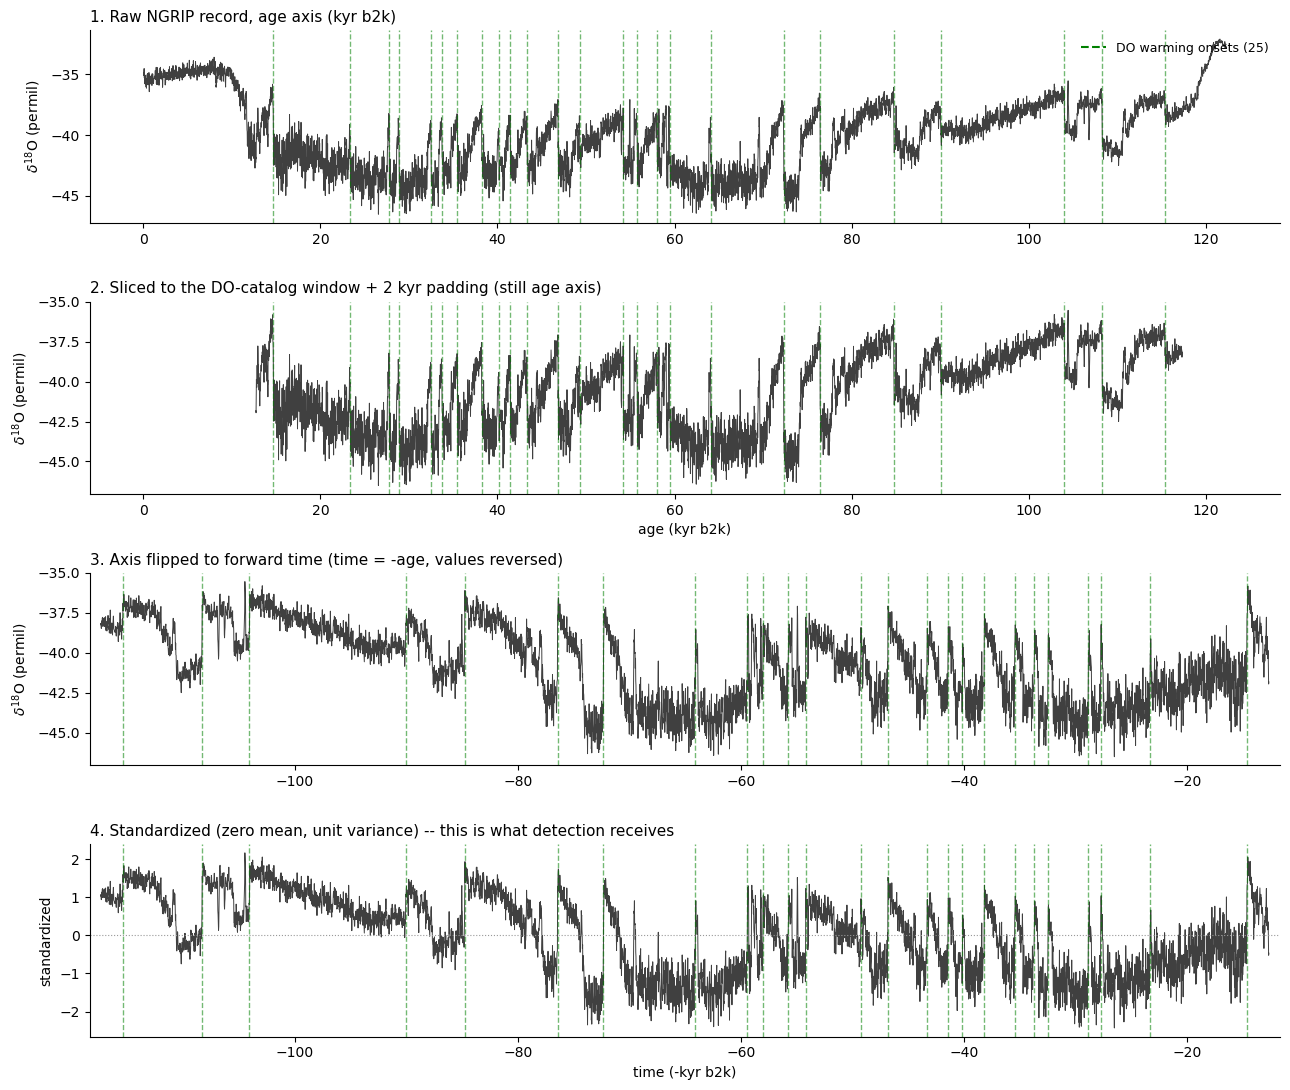

In [ ]:
AMMONYTE_DATA_DIR = "/Users/maryamniati/Documents/Ammonyte/ammonyte/ammonyte/data"
PADDING_KYR = 2.0

ngrip = pd.read_csv(os.path.join(AMMONYTE_DATA_DIR, "NGRIP.csv"), skiprows=8, header=None,
                    names=["age", "d18O", "extra"]).dropna(subset=["age", "d18O"])
age = ngrip["age"].values.astype(float)           # kyr b2k, ascending
d18o = ngrip["d18O"].values.astype(float)

do = pd.read_csv(os.path.join(AMMONYTE_DATA_DIR, "DO_onsets_Rasmussen2014.csv"), comment="#")
do_age = np.sort(do["main25_kyr_b2k"].dropna().values.astype(float))     # the 25 main onsets

# step 2: slice to the DO window + padding
lo, hi = do_age.min() - PADDING_KYR, do_age.max() + PADDING_KYR
m = (age >= lo) & (age <= hi)
age_win, d18o_win = age[m], d18o[m]

# step 3: flip the axis -> forward time (time = -age ascending, values reversed)
t_fwd = -age_win[::-1]
x_fwd = d18o_win[::-1]
do_fwd = np.sort(-do_age)

# step 4: standardize
x_fwd_std = standardize_1d(x_fwd)

summary = pd.DataFrame({
    "step": ["1. raw record", "2. sliced window", "3. flipped (forward time)", "4. standardized"],
    "points": [len(age), len(age_win), len(x_fwd), len(x_fwd_std)],
    "time range": [f"{age.min():.1f} to {age.max():.1f} kyr b2k", f"{age_win.min():.1f} to {age_win.max():.1f} kyr b2k",
                   f"{t_fwd.min():.1f} to {t_fwd.max():.1f} (-kyr b2k)", f"{t_fwd.min():.1f} to {t_fwd.max():.1f} (-kyr b2k)"],
    "mean": [d18o.mean(), d18o_win.mean(), x_fwd.mean(), x_fwd_std.mean()],
    "std": [d18o.std(ddof=1), d18o_win.std(ddof=1), x_fwd.std(ddof=1), x_fwd_std.std(ddof=1)],
}).set_index("step").round(3)
print(f"{len(do_age)} DO onsets, {do_age.min():.2f}-{do_age.max():.2f} kyr b2k")
display(summary)

fig, axes = plt.subplots(4, 1, figsize=(13, 11))
ax = axes[0]
ax.plot(age, d18o, color="0.25", linewidth=0.7)
ax.set_title("1. Raw NGRIP record, age axis (kyr b2k)", loc="left", fontsize=11)
ax.set_ylabel("$\\delta^{18}$O (permil)")

ax = axes[1]
ax.plot(age_win, d18o_win, color="0.25", linewidth=0.7)
ax.set_title(f"2. Sliced to the DO-catalog window + {PADDING_KYR:g} kyr padding (still age axis)", loc="left", fontsize=11)
ax.set_ylabel("$\\delta^{18}$O (permil)")

ax = axes[2]
ax.plot(t_fwd, x_fwd, color="0.25", linewidth=0.7)
ax.set_title("3. Axis flipped to forward time (time = -age, values reversed)", loc="left", fontsize=11)
ax.set_ylabel("$\\delta^{18}$O (permil)")

ax = axes[3]
ax.plot(t_fwd, x_fwd_std, color="0.25", linewidth=0.7)
ax.axhline(0, color="0.6", linewidth=0.8, linestyle=":")
ax.set_title("4. Standardized (zero mean, unit variance) -- this is what detection receives", loc="left", fontsize=11)
ax.set_ylabel("standardized")

for ax, onsets in zip(axes, (do_age, do_age, do_fwd, do_fwd)):
    for o in onsets:
        ax.axvline(o, color="green", linestyle="--", linewidth=1.0, alpha=0.55)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].plot([], [], color="green", linestyle="--", label=f"DO warming onsets ({len(do_age)})")
axes[0].legend(loc="upper right", fontsize=9, frameon=False)
axes[1].set_xlim(axes[0].get_xlim())
axes[1].set_xlabel("age (kyr b2k)")
axes[2].set_xlim(t_fwd.min() - 1, t_fwd.max() + 1)
axes[3].set_xlim(axes[2].get_xlim())
axes[3].set_xlabel("time (-kyr b2k)")
fig.tight_layout()
plt.show()